# RAG evaluation

Evaluates `rag_system.py` in two modes: **rag** (retriever + generator) and **norag** (LLM alone, baseline).

Metrics follow the course slides ("LLM-based Agents"):

- Both modes: JudgeRating (0-10, slide prompt), JudgeScore (0-10, vs the reference answer), Correctness (Ragas pass/fail), AnswerRelevance, BLEU, ROUGE-L, Token F1
- RAG only: P@k, R@k, Hit Rate@k, MRR, Context Precision/Recall, Faithfulness, and retrieval vs generation errors
- Slow: answers (Ollama); LLM-as-judge and Ragas (judge on OpenRouter, needs `OPENROUTER_API_KEY` in `.env`)

Ground truth format:

```json
[{"query_id": 1,
  "user_query": "Quem matou os pais de Bruce Wayne?",
  "ground_truth_doc_ids": ["doc_1"],
  "ground_truth_answer": "Joe Chill."}]
```

Doc ids: `"doc_1"`, `"wiki_batman.pdf"` or `"doc_1#p3"` (page 3).

## 1. Setup

In [1]:
import csv
import json
import math
import os
import re
import sys
import time

import pandas as pd
from dotenv import load_dotenv

# The kernel usually starts in rag/evaluation/, but may start in rag/ or the project root.
# rag_system.py (in rag/) resolves its own data paths (pdffiles/, iln_batman/).
EVAL_DIR = next(
    d for d in (os.getcwd(), os.path.join(os.getcwd(), "evaluation"), os.path.join(os.getcwd(), "rag", "evaluation"))
    if os.path.exists(os.path.join(d, "metrics.py"))
)
D2_DIR = os.path.dirname(EVAL_DIR)
sys.path[:0] = [EVAL_DIR, D2_DIR]
os.chdir(D2_DIR)

import metrics as M
import rag_system as rag

/Users/miguelmauricioantonio/Documents/MIA/2/ILN/PROJECT/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 13678.80it/s]


In [2]:
GROUND_TRUTH = os.path.join(EVAL_DIR, "ground_truth_example.json")
KS = [1, 3, 5]                 # cut-offs for P@k and R@k
GEN_K = 3                      # chunks passed to the generator, a¯s in responder_com_rag
RETRIEVER = "denso"          # "hibrido" (dense + BM25 with RRF), "denso" or "bm25"
# Judge for Ragas + JudgeScore, on OpenRouter: a larger model from another family than the generator
JUDGE_MODEL = "google/gemma-4-31b-it"
JUDGE_URL = "https://openrouter.ai/api/v1"
load_dotenv(os.path.join(os.path.dirname(D2_DIR), ".env"))   # D2_D3_Miguel_Luís/.env
JUDGE_API_KEY = os.environ.get("OPENROUTER_API_KEY")
if not JUDGE_API_KEY:
    raise RuntimeError("Missing OPENROUTER_API_KEY (in .env or the environment) for the judge.")
N_QUESTIONS = 3                # N for Answer Relevance

# Outputs are saved here and reused if they already exist.
# Point it at an old run (evaluation/results/<name>) to re-score it without regenerating.
OUT_DIR = os.path.join(EVAL_DIR, "results", f"notebook_{RETRIEVER}")

### Document ids

In [3]:
catalog = {f"doc_{i}": nome for i, nome in enumerate(rag.FONTES_PDF, start=1)}  # doc_N -> PDF file name

_GT_ID_RE = re.compile(r"^(?P<doc>[^#]+?)(?:#p(?P<page>\d+))?$")


def parse_gt_id(gt_id):
    """Returns (pdf_name, page or None)."""
    match = _GT_ID_RE.match(gt_id.strip())
    if not match:
        raise ValueError(f"Invalid ground-truth doc id: {gt_id!r}")
    doc, page = match.group("doc"), match.group("page")
    nome = catalog.get(doc, doc)
    if nome not in catalog.values():
        raise ValueError(f"Unknown ground-truth doc id {gt_id!r}; see the doc_id -> PDF table")
    return nome, (int(page) if page else None)


pd.Series(catalog, name="pdf").to_frame()

,pdf
doc_1,wiki_batman.pdf
doc_2,wiki_gotham_city.pdf
doc_3,wiki_asilo_arkham.pdf
doc_4,wiki_batcaverna.pdf
doc_5,wiki_batmovel.pdf
doc_6,wiki_alfred_pennyworth.pdf
doc_7,wiki_james_gordon.pdf
doc_8,wiki_robin.pdf
doc_9,wiki_coringa.pdf
doc_10,wiki_pinguim.pdf


### Ground truth

In [4]:
def load_ground_truth(path):
    """Loads and validates the ground truth."""
    with open(path, encoding="utf-8") as f:
        data = json.load(f)
    required = {"query_id", "user_query", "ground_truth_doc_ids", "ground_truth_answer"}
    for item in data:
        missing = required - item.keys()
        if missing:
            raise ValueError(f"query {item.get('query_id', '?')}: missing fields {sorted(missing)}")
        for gt_id in item["ground_truth_doc_ids"]:  # validate doc ids early
            parse_gt_id(gt_id)
    return data


ground_truth = load_ground_truth(GROUND_TRUTH)
print(f"{len(ground_truth)} queries")

15 queries


## 2. Answers

In [5]:
def run_rag(ground_truth, retrieve_k, gen_k, retriever):
    """Runs retriever + generator for each query."""
    db = rag.obter_ou_criar_vector_db(rag.descarregar_pdfs())
    doc_id_by_name = {nome: doc_id for doc_id, nome in catalog.items()}

    outputs = []
    for i, item in enumerate(ground_truth, start=1):
        print(f"[RAG {i}/{len(ground_truth)}] {item['user_query']}")
        t0 = time.time()
        docs = rag.recuperar_chunks(item["user_query"], db, k=retrieve_k, modo=retriever)
        t_ret = time.time() - t0
        answer = rag.gerar_resposta(item["user_query"], docs[:gen_k])
        t_gen = time.time() - t0 - t_ret
        outputs.append({
            **item,
            "generated_answer": M.strip_thinking(answer),
            "retrieved": [
                {
                    "rank": rank,
                    "doc_id": doc_id_by_name.get(re.split(r"[\\/]", d.metadata.get("source", ""))[-1], "?"),
                    "source": d.metadata.get("source", ""),
                    "page": int(d.metadata.get("page", -1)) + 1,  # 1-based
                    "content": d.page_content,
                }
                for rank, d in enumerate(docs, start=1)
            ],
            "mode": "rag",
            "gen_k": gen_k,
            "retriever": retriever,
            "retrieval_seconds": round(t_ret, 3),
            "generation_seconds": round(t_gen, 3),
        })
    return outputs


def run_norag(ground_truth):
    """Baseline: the same LLM answers each query alone, with no retrieved context."""
    outputs = []
    for i, item in enumerate(ground_truth, start=1):
        print(f"[NO-RAG {i}/{len(ground_truth)}] {item['user_query']}")
        t0 = time.time()
        answer = rag.responder_sem_rag(item["user_query"])
        outputs.append({
            **item,
            "generated_answer": M.strip_thinking(answer),
            "retrieved": [],
            "mode": "norag",
            "gen_k": 0,
            "retriever": None,
            "retrieval_seconds": 0.0,
            "generation_seconds": round(time.time() - t0, 3),
        })
    return outputs


def load_or_run(mode, run):
    """Loads <OUT_DIR>/<mode>/outputs.json, or runs `run()` and saves it."""
    path = os.path.join(OUT_DIR, mode, "outputs.json")
    if os.path.exists(path):
        with open(path, encoding="utf-8") as f:
            outputs = json.load(f)
        print(f"Reusing {len(outputs)} {mode} outputs from {path}")
        return outputs
    outputs = run()
    os.makedirs(os.path.dirname(path), exist_ok=True)
    with open(path, "w", encoding="utf-8") as f:
        json.dump(outputs, f, ensure_ascii=False, indent=2)
    return outputs


outputs_by_mode = {}

In [6]:
outputs_by_mode["rag"] = load_or_run(
    "rag", lambda: run_rag(ground_truth, retrieve_k=max(KS + [GEN_K]), gen_k=GEN_K, retriever=RETRIEVER))

Reusing 15 rag outputs from /Users/miguelmauricioantonio/Documents/MIA/2/ILN/PROJECT/D2_D3_Miguel_Luís/rag/evaluation/results/notebook_denso/rag/outputs.json


In [7]:
outputs_by_mode["norag"] = load_or_run("norag", lambda: run_norag(ground_truth))

Reusing 15 norag outputs from /Users/miguelmauricioantonio/Documents/MIA/2/ILN/PROJECT/D2_D3_Miguel_Luís/rag/evaluation/results/notebook_denso/norag/outputs.json


## 3. Metrics

Each cell fills `scores[mode][group]`, indexed by `query_id`.

In [8]:
scores = {mode: {} for mode in outputs_by_mode}
details = {mode: {out["query_id"]: {} for out in outputs} for mode, outputs in outputs_by_mode.items()}


def to_df(rows):
    return pd.DataFrame(rows).set_index("query_id")


def show(mode, group):
    df = scores[mode][group]
    display(df)
    display(df.mean().to_frame(f"mean ({mode})").T)

### 3.1 Retrieval: P@k, R@k, Hit Rate@k, MRR (RAG only)

Relevant chunk = from a ground-truth document (or page).

In [17]:
def file_name(path):
    """File name from a path saved on any OS (outputs.json may come from Windows, with backslashes)."""
    return re.split(r"[\\/]", path)[-1]


def chunk_hits(chunk, gt_ids):
    """Ground-truth ids matched by a chunk."""
    nome = file_name(chunk["source"])
    hits = set()
    for gt_id in gt_ids:
        gt_nome, gt_page = parse_gt_id(gt_id)
        if nome == gt_nome and (gt_page is None or chunk["page"] == gt_page):
            hits.add(gt_id)
    return hits


outputs = outputs_by_mode["rag"]
ks = [k for k in KS if k <= len(outputs[0]["retrieved"])]
rows = []
for out in outputs:
    gt_ids = out["ground_truth_doc_ids"]
    hits = [chunk_hits(c, gt_ids) for c in out["retrieved"]]
    relevance = [int(bool(h)) for h in hits]
    row = {"query_id": out["query_id"]}
    for k in ks:
        row[f"P@{k}"] = M.precision_at_k(relevance, k)
        row[f"R@{k}"] = M.recall_at_k(hits, gt_ids, k)
        row[f"Hit@{k}"] = M.hit_rate_at_k(relevance, k)
    row["MRR"] = M.reciprocal_rank(relevance)
    rows.append(row)
    details["rag"][out["query_id"]].update({"relevance": relevance, "hit_ids": [sorted(h) for h in hits]})
scores["rag"]["retrieval"] = to_df(rows)
show("rag", "retrieval")

,P@1,R@1,Hit@1,P@3,R@3,Hit@3,P@5,R@5,Hit@5,MRR
query_id,,,,,,,,,,
1,0.0,0.0,0.0,0.666667,1.0,1.0,0.8,1.0,1.0,0.500000
2,1.0,1.0,1.0,1.000000,1.0,1.0,0.8,1.0,1.0,1.000000
3,1.0,0.5,1.0,1.000000,0.5,1.0,1.0,0.5,1.0,1.000000
4,1.0,1.0,1.0,0.666667,1.0,1.0,0.8,1.0,1.0,1.000000
5,1.0,1.0,1.0,1.000000,1.0,1.0,0.8,1.0,1.0,1.000000
6,1.0,1.0,1.0,1.000000,1.0,1.0,0.8,1.0,1.0,1.000000
7,0.0,0.0,0.0,0.333333,1.0,1.0,0.2,1.0,1.0,0.333333
8,1.0,1.0,1.0,1.000000,1.0,1.0,1.0,1.0,1.0,1.000000
9,1.0,1.0,1.0,1.000000,1.0,1.0,0.8,1.0,1.0,1.000000


,P@1,R@1,Hit@1,P@3,R@3,Hit@3,P@5,R@5,Hit@5,MRR
mean (rag),0.866667,0.833333,0.866667,0.8,0.966667,1.0,0.72,0.966667,1.0,0.922222


### 3.2 Token F1 (both modes, no LLM)

In [10]:
for mode, outputs in outputs_by_mode.items():
    rows = []
    for out in outputs:
        f1, precision, recall = M.token_f1(out["generated_answer"], out["ground_truth_answer"])
        rows.append({"query_id": out["query_id"], "TokenF1": f1, "TokenPrecision": precision, "TokenRecall": recall})
    scores[mode]["token"] = to_df(rows)
    show(mode, "token")

,TokenF1,TokenPrecision,TokenRecall
query_id,,,
1,0.470588,0.500000,0.444444
2,0.875000,0.875000,0.875000
3,0.444444,0.285714,1.000000
4,0.615385,0.500000,0.800000
5,0.347826,0.363636,0.333333
6,0.400000,0.285714,0.666667
7,0.186047,0.500000,0.114286
8,0.507042,0.400000,0.692308
9,0.764706,0.619048,1.000000


,TokenF1,TokenPrecision,TokenRecall
mean (rag),0.57276,0.532835,0.702092


,TokenF1,TokenPrecision,TokenRecall
query_id,,,
1,0.257143,0.147541,1.000000
2,0.122137,0.069565,0.500000
3,0.000000,0.000000,0.000000
4,0.450000,0.300000,0.900000
5,0.258065,0.160000,0.666667
6,0.400000,0.285714,0.666667
7,0.142132,0.086420,0.400000
8,0.084615,0.047009,0.423077
9,0.045714,0.024691,0.307692


,TokenF1,TokenPrecision,TokenRecall
mean (norag),0.171838,0.106979,0.522089


### 3.3 LLM-as-judge, 0-10 (both modes, OpenRouter judge)

- **JudgeRating**: the prompt from the slides ("total rating", question and answer only).
- **JudgeScore**: `rag.avaliar_resposta_llm_judge`, which also sees the reference answer.

In [11]:
from types import SimpleNamespace

from openai import OpenAI

judge_client = OpenAI(base_url=JUDGE_URL, api_key=JUDGE_API_KEY)


class Judge:
    """OpenRouter judge with the .invoke(prompt).content interface that rag_system expects."""

    def invoke(self, prompt):
        r = judge_client.chat.completions.create(
            model=JUDGE_MODEL, temperature=0, messages=[{"role": "user", "content": prompt}])
        return SimpleNamespace(content=r.choices[0].message.content or "")


judge = Judge()
for mode, outputs in outputs_by_mode.items():
    rows = []
    for i, out in enumerate(outputs, start=1):
        print(f"[Judge {i}/{len(outputs)}] query {out['query_id']} ({mode})")
        feedback = judge.invoke(M.JUDGE_PROMPT.format(
            question=out["user_query"], answer=out["generated_answer"])).content
        rating = M.extract_rating(feedback)
        details[mode][out["query_id"]]["judge_feedback"] = feedback.strip()
        score = rag.avaliar_resposta_llm_judge(
            out["user_query"], out["generated_answer"], out["ground_truth_answer"], juiz=judge)
        rows.append({"query_id": out["query_id"], "JudgeRating": rating, "JudgeScore": score})
    scores[mode]["judge"] = to_df(rows)
    show(mode, "judge")

[Judge 1/15] query 1 (rag)
[Judge 2/15] query 2 (rag)
[Judge 3/15] query 3 (rag)
[Judge 4/15] query 4 (rag)
[Judge 5/15] query 5 (rag)
[Judge 6/15] query 6 (rag)
[Judge 7/15] query 7 (rag)
[Judge 8/15] query 8 (rag)
[Judge 9/15] query 9 (rag)
[Judge 10/15] query 10 (rag)
[Judge 11/15] query 11 (rag)
[Judge 12/15] query 12 (rag)
[Judge 13/15] query 13 (rag)
[Judge 14/15] query 14 (rag)
[Judge 15/15] query 15 (rag)


,JudgeRating,JudgeScore
query_id,,
1,0.0,0.0
2,10.0,10.0
3,10.0,10.0
4,10.0,10.0
5,10.0,10.0
6,10.0,8.0
7,0.0,0.0
8,10.0,10.0
9,5.0,10.0


,JudgeRating,JudgeScore
mean (rag),8.333333,8.466667


[Judge 1/15] query 1 (norag)
[Judge 2/15] query 2 (norag)
[Judge 3/15] query 3 (norag)
[Judge 4/15] query 4 (norag)
[Judge 5/15] query 5 (norag)
[Judge 6/15] query 6 (norag)
[Judge 7/15] query 7 (norag)
[Judge 8/15] query 8 (norag)
[Judge 9/15] query 9 (norag)
[Judge 10/15] query 10 (norag)
[Judge 11/15] query 11 (norag)
[Judge 12/15] query 12 (norag)
[Judge 13/15] query 13 (norag)
[Judge 14/15] query 14 (norag)
[Judge 15/15] query 15 (norag)


,JudgeRating,JudgeScore
query_id,,
1,10.0,10.0
2,1.0,0.0
3,3.0,2.0
4,10.0,10.0
5,10.0,10.0
6,10.0,8.0
7,1.0,0.0
8,3.0,0.0
9,4.0,2.0


,JudgeRating,JudgeScore
mean (norag),6.666667,3.533333


### 3.4 Ragas (OpenRouter judge)

No-RAG computes only Answer Relevance.

In [12]:
evaluator = M.RagasEvaluator(JUDGE_MODEL, rag.embedding_func.model_name, N_QUESTIONS,
                             base_url=JUDGE_URL, api_key=JUDGE_API_KEY, reasoning_effort=None)
for mode, outputs in outputs_by_mode.items():
    rows = []
    for i, out in enumerate(outputs, start=1):
        print(f"[Ragas {i}/{len(outputs)}] query {out['query_id']} ({mode})")
        contexts = [c["content"] for c in out["retrieved"][:out["gen_k"]]]
        # Without context only Answer Relevance is defined
        only = None if mode == "rag" else ["AnswerRelevance"]
        # Top-level await: Jupyter already runs an event loop
        row, errors = await evaluator.ascore(
            out["user_query"], out["ground_truth_answer"], out["generated_answer"], contexts, only=only)
        row = {(f"ContextPrecision@{out['gen_k']}" if n == "ContextPrecision" else n): v for n, v in row.items()}
        for name, error in errors.items():
            print(f"  {name} failed: {error}")
            details[mode][out["query_id"]].setdefault("ragas_errors", {})[name] = error
        rows.append({"query_id": out["query_id"], **row})
    scores[mode]["ragas"] = to_df(rows)
    show(mode, "ragas")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 17879.84it/s]


[Ragas 1/15] query 1 (rag)
[Ragas 2/15] query 2 (rag)
[Ragas 3/15] query 3 (rag)
[Ragas 4/15] query 4 (rag)
[Ragas 5/15] query 5 (rag)
[Ragas 6/15] query 6 (rag)
[Ragas 7/15] query 7 (rag)
[Ragas 8/15] query 8 (rag)
[Ragas 9/15] query 9 (rag)
[Ragas 10/15] query 10 (rag)
[Ragas 11/15] query 11 (rag)
[Ragas 12/15] query 12 (rag)
[Ragas 13/15] query 13 (rag)
[Ragas 14/15] query 14 (rag)
[Ragas 15/15] query 15 (rag)


,ContextPrecision@3,ContextRecall,Faithfulness,AnswerRelevance
query_id,,,,
1,0.000000,0.0,0.0,1.000000
2,1.000000,1.0,1.0,0.966158
3,1.000000,1.0,1.0,0.800286
4,0.333333,1.0,1.0,0.974138
5,0.583333,1.0,1.0,0.655557
6,1.000000,0.0,1.0,1.000000
7,0.000000,0.0,0.0,0.000000
8,0.500000,1.0,1.0,0.900157
9,0.333333,1.0,1.0,0.996817


,ContextPrecision@3,ContextRecall,Faithfulness,AnswerRelevance
mean (rag),0.672222,0.8,0.866667,0.85566


[Ragas 1/15] query 1 (norag)
[Ragas 2/15] query 2 (norag)
[Ragas 3/15] query 3 (norag)
[Ragas 4/15] query 4 (norag)
[Ragas 5/15] query 5 (norag)
[Ragas 6/15] query 6 (norag)
[Ragas 7/15] query 7 (norag)
[Ragas 8/15] query 8 (norag)
[Ragas 9/15] query 9 (norag)
[Ragas 10/15] query 10 (norag)
[Ragas 11/15] query 11 (norag)
[Ragas 12/15] query 12 (norag)
[Ragas 13/15] query 13 (norag)
[Ragas 14/15] query 14 (norag)
[Ragas 15/15] query 15 (norag)


,AnswerRelevance
query_id,
1,0.924014
2,0.648107
3,0.885467
4,0.988972
5,0.929059
6,1.000000
7,0.564115
8,0.655198
9,0.958813


,AnswerRelevance
mean (norag),0.864243


### 3.5 Correctness, BLEU, ROUGE-L (both modes, Ragas)

- **Correctness**: Ragas `DiscreteMetric` pass/fail with the prompt from the slides, judged by the OpenRouter model. Stored as 1 (pass) / 0 (fail), so its mean is the pass rate. The context is the chunks given to the generator (none in no-RAG).
- **BLEU / ROUGE-L**: Ragas `BleuScore` / `RougeScore` against the reference answer. They need `pip install sacrebleu rouge_score`; without them they are skipped.

In [13]:
from openai import AsyncOpenAI
from ragas.llms import llm_factory

judge_client_async = AsyncOpenAI(base_url=JUDGE_URL, api_key=JUDGE_API_KEY)
judge_llm = llm_factory(JUDGE_MODEL, provider="openai", client=judge_client_async, temperature=0, max_tokens=4096)
correctness = M.make_correctness_metric()

try:
    import sacrebleu  # noqa: F401
    import rouge_score  # noqa: F401
    from ragas.metrics.collections import BleuScore, RougeScore
    bleu, rouge = BleuScore(), RougeScore(rouge_type="rougeL")
except ImportError:
    bleu = rouge = None
    print("BLEU/ROUGE-L skipped (pip install sacrebleu rouge_score)")

for mode, outputs in outputs_by_mode.items():
    correctness_rows, lexical_rows = [], []
    for i, out in enumerate(outputs, start=1):
        print(f"[Correctness {i}/{len(outputs)}] query {out['query_id']} ({mode})")
        contexts = [c["content"] for c in out["retrieved"][:out["gen_k"]]]
        try:
            result = await correctness.ascore(
                llm=judge_llm, question=out["user_query"], expected_answer=out["ground_truth_answer"],
                context="\n\n".join(contexts) or "(no context)", response=out["generated_answer"])
            value = {"pass": 1.0, "fail": 0.0}.get(result.value, math.nan)
            details[mode][out["query_id"]]["correctness_reason"] = result.reason
        except Exception as e:
            value = math.nan
            print(f"  Correctness failed: {type(e).__name__}: {e}")
            details[mode][out["query_id"]]["correctness_reason"] = f"ERROR: {type(e).__name__}: {e}"
        correctness_rows.append({"query_id": out["query_id"], "Correctness": value})

        if bleu:
            lexical_rows.append({
                "query_id": out["query_id"],
                "BLEU": (await bleu.ascore(reference=out["ground_truth_answer"], response=out["generated_answer"])).value,
                "ROUGE-L": (await rouge.ascore(reference=out["ground_truth_answer"], response=out["generated_answer"])).value,
            })
    scores[mode]["correctness"] = to_df(correctness_rows)
    show(mode, "correctness")
    if lexical_rows:
        scores[mode]["lexical"] = to_df(lexical_rows)
        show(mode, "lexical")

[Correctness 1/15] query 1 (rag)
[Correctness 2/15] query 2 (rag)
[Correctness 3/15] query 3 (rag)
[Correctness 4/15] query 4 (rag)
[Correctness 5/15] query 5 (rag)
[Correctness 6/15] query 6 (rag)
[Correctness 7/15] query 7 (rag)
[Correctness 8/15] query 8 (rag)
[Correctness 9/15] query 9 (rag)
[Correctness 10/15] query 10 (rag)
[Correctness 11/15] query 11 (rag)
[Correctness 12/15] query 12 (rag)
[Correctness 13/15] query 13 (rag)
[Correctness 14/15] query 14 (rag)
[Correctness 15/15] query 15 (rag)


,Correctness
query_id,
1,0.0
2,1.0
3,1.0
4,1.0
5,1.0
6,1.0
7,0.0
8,1.0
9,1.0


,Correctness
mean (rag),0.866667


,BLEU,ROUGE-L
query_id,,
1,0.259654,0.500000
2,0.744373,0.914286
3,0.177474,0.444444
4,0.121090,0.551724
5,0.084931,0.230769
6,0.105527,0.400000
7,0.012878,0.214286
8,0.060773,0.303797
9,0.704437,0.744186


,BLEU,ROUGE-L
mean (rag),0.289091,0.54558


[Correctness 1/15] query 1 (norag)
[Correctness 2/15] query 2 (norag)
[Correctness 3/15] query 3 (norag)
[Correctness 4/15] query 4 (norag)
[Correctness 5/15] query 5 (norag)
[Correctness 6/15] query 6 (norag)
[Correctness 7/15] query 7 (norag)
[Correctness 8/15] query 8 (norag)
[Correctness 9/15] query 9 (norag)
[Correctness 10/15] query 10 (norag)
[Correctness 11/15] query 11 (norag)
[Correctness 12/15] query 12 (norag)
[Correctness 13/15] query 13 (norag)
[Correctness 14/15] query 14 (norag)
[Correctness 15/15] query 15 (norag)


,Correctness
query_id,
1,1.0
2,0.0
3,0.0
4,1.0
5,1.0
6,1.0
7,0.0
8,0.0
9,0.0


,Correctness
mean (norag),0.266667


,BLEU,ROUGE-L
query_id,,
1,0.259838,0.240964
2,0.084754,0.101911
3,0.000000,0.000000
4,0.085624,0.444444
5,0.245039,0.228571
6,0.105527,0.400000
7,0.103496,0.120482
8,0.063532,0.067901
9,0.017912,0.058537


,BLEU,ROUGE-L
mean (norag),0.104689,0.164031


### 3.6 Retrieval vs generation errors (RAG only)

As in the slides: a failed answer (Correctness = 0) is a **retrieval error** if no relevant chunk was among the `gen_k` chunks given to the generator, and a **generation error** if one was. Saved to `OUT_DIR/rag/error_analysis.csv`.

In [18]:
rows = []
for out in outputs_by_mode["rag"]:
    qid = out["query_id"]
    if scores["rag"]["correctness"].loc[qid, "Correctness"] != 0:
        continue  # passed, or the judge failed (NaN)
    relevance = details["rag"][qid]["relevance"]
    error_type = "generation" if any(relevance[:out["gen_k"]]) else "retrieval"
    details["rag"][qid]["error_type"] = error_type
    rows.append({"query_id": qid, "error_type": error_type, "user_query": out["user_query"],
                 "reason": details["rag"][qid].get("correctness_reason", "")})

errors = pd.DataFrame(rows, columns=["query_id", "error_type", "user_query", "reason"])
n_rag = len(outputs_by_mode["rag"])
display(errors["error_type"].value_counts().reindex(["retrieval", "generation"], fill_value=0)
        .to_frame("failed answers").assign(share_of_queries=lambda d: (d["failed answers"] / n_rag).round(3)))
display(errors)
os.makedirs(os.path.join(OUT_DIR, "rag"), exist_ok=True)
errors.to_csv(os.path.join(OUT_DIR, "rag", "error_analysis.csv"), index=False)

,failed answers,share_of_queries
error_type,,
retrieval,0,0.000
generation,2,0.133


,query_id,error_type,user_query,reason
0,1,generation,Quem assassinou os pais de Bruce Wayne?,The model response states that 'capangas de Ce...
1,7,generation,O que é o Poço de Lázaro?,The model response states that there are no re...


## 4. Summary

Saves `per_query.csv`, `per_query_details.json` and `summary.json` to `OUT_DIR/<mode>/`.

In [19]:
GROUP_ORDER = ["retrieval", "ragas", "judge", "correctness", "lexical", "token"]
tables, means = {}, {}

for mode, outputs in outputs_by_mode.items():
    groups = [scores[mode][g] for g in GROUP_ORDER if g in scores[mode]]
    if not groups:
        continue
    table = pd.concat(groups, axis=1).loc[[out["query_id"] for out in outputs]]
    tables[mode] = table
    means[mode] = table.mean()  # NaN (failed metric) is skipped

    mode_dir = os.path.join(OUT_DIR, mode)
    os.makedirs(mode_dir, exist_ok=True)
    table.to_csv(os.path.join(mode_dir, "per_query.csv"))
    full = [{**out, "metrics": table.loc[out["query_id"]].to_dict(), "details": details[mode][out["query_id"]]}
            for out in outputs]
    with open(os.path.join(mode_dir, "per_query_details.json"), "w", encoding="utf-8") as f:
        json.dump(full, f, ensure_ascii=False, indent=2)
    config = {
        "mode": mode,
        "ground_truth": GROUND_TRUTH,
        "n_queries": len(outputs),
        "k": ks if mode == "rag" and "retrieval" in scores[mode] else [],
        "gen_k": outputs[0]["gen_k"],
        "retriever": outputs[0].get("retriever"),
        "generator_model": getattr(rag.llm, "model", None) or getattr(rag.llm, "model_name", None),
        "judge_model": JUDGE_MODEL if {"judge", "ragas", "correctness"} & scores[mode].keys() else None,
        "embedding_model": rag.embedding_func.model_name,
        "n_questions": N_QUESTIONS,
        "metric_groups": [g for g in GROUP_ORDER if g in scores[mode]],
    }
    summary = {m: {"mean": means[mode][m], "n": int(table[m].notna().sum())} for m in table.columns}
    with open(os.path.join(mode_dir, "summary.json"), "w", encoding="utf-8") as f:
        json.dump({"config": config, "metrics": summary}, f, ensure_ascii=False, indent=2)

pd.DataFrame(means).round(3)

,rag,norag
AnswerRelevance,0.856,0.864
BLEU,0.289,0.105
ContextPrecision@3,0.672,NaN
ContextRecall,0.800,NaN
Correctness,0.867,0.267
Faithfulness,0.867,NaN
Hit@1,0.867,NaN
Hit@3,1.000,NaN
Hit@5,1.000,NaN
JudgeRating,8.333,6.667


### With vs without RAG

Means, per-query wins/ties/losses and a Wilcoxon test. Saved to `OUT_DIR/comparison.{csv,json}`.

In [20]:
from scipy.stats import wilcoxon

PAIRED_METRICS = ["JudgeRating", "JudgeScore", "Correctness", "AnswerRelevance", "BLEU", "ROUGE-L", "TokenF1"]

shared = [m for m in tables["rag"].columns if m in tables["norag"].columns]
comparison = pd.DataFrame({"norag": means["norag"][shared], "rag": means["rag"][shared]})
comparison["delta"] = comparison["rag"] - comparison["norag"]
display(comparison.round(3))

paired = {}
for m in [m for m in PAIRED_METRICS if m in shared]:
    pairs = pd.concat([tables["rag"][m], tables["norag"][m]], axis=1, keys=["rag", "norag"]).dropna()
    diff = pairs["rag"] - pairs["norag"]
    wins, ties, losses = int((diff > 0).sum()), int((diff == 0).sum()), int((diff < 0).sum())
    p_value = float(wilcoxon(pairs["rag"], pairs["norag"]).pvalue) if wins + losses > 0 else float("nan")
    paired[m] = {"n": len(pairs), "wins": wins, "ties": ties, "losses": losses, "wilcoxon_p": p_value}
display(pd.DataFrame(paired).T)

comparison.to_csv(os.path.join(OUT_DIR, "comparison.csv"), index_label="metric")
with open(os.path.join(OUT_DIR, "comparison.json"), "w", encoding="utf-8") as f:
    json.dump({"metrics": comparison.to_dict("index"), "paired": paired}, f, ensure_ascii=False, indent=2)
print(f"Results saved to {OUT_DIR}")

,norag,rag,delta
AnswerRelevance,0.864,0.856,-0.009
JudgeRating,6.667,8.333,1.667
JudgeScore,3.533,8.467,4.933
Correctness,0.267,0.867,0.600
BLEU,0.105,0.289,0.184
ROUGE-L,0.164,0.546,0.382
TokenF1,0.172,0.573,0.401
TokenPrecision,0.107,0.533,0.426
TokenRecall,0.522,0.702,0.180


,n,wins,ties,losses,wilcoxon_p
JudgeRating,15.0,7.0,6.0,2.0,0.154044
JudgeScore,15.0,10.0,4.0,1.0,0.026314
Correctness,15.0,10.0,4.0,1.0,0.006656
AnswerRelevance,15.0,7.0,1.0,7.0,0.729891
BLEU,15.0,10.0,1.0,4.0,0.018567
ROUGE-L,15.0,14.0,1.0,0.0,0.000982
TokenF1,15.0,14.0,1.0,0.0,0.000982


Results saved to /Users/miguelmauricioantonio/Documents/MIA/2/ILN/PROJECT/D2_D3_Miguel_Luís/rag/evaluation/results/notebook_denso


## 5. Plots

Figures for the report, saved as 300-dpi PNGs to `OUT_DIR/plots/`. RAG is always blue and no-RAG always orange. With 15 questions the intervals are wide, so read differences together with the Wilcoxon p-values from section 4.

In [22]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap

PLOT_DIR = os.path.join(OUT_DIR, "plots")
os.makedirs(PLOT_DIR, exist_ok=True)

COLORS = {"rag": "#2a78d6", "norag": "#eb6834"}  # fixed per mode in every plot
LABELS = {"rag": "RAG", "norag": "No RAG"}
INK, MUTED, GRID, CONNECTOR = "#0b0b0b", "#52514e", "#e4e3df", "#c3c2b7"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
    "axes.labelcolor": INK, "axes.titlecolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False,
})


def bootstrap_ci(values, n_boot=10_000, seed=0):
    """Mean and 95% percentile-bootstrap CI of the mean (NaN ignored)."""
    v = pd.Series(values).dropna().to_numpy(dtype=float)
    if len(v) == 0:
        return np.nan, np.nan, np.nan
    boots = np.random.default_rng(seed).choice(v, size=(n_boot, len(v))).mean(axis=1)
    return v.mean(), *np.percentile(boots, [2.5, 97.5])


def p_text(metric):
    """Wilcoxon p-value from section 4, as a label."""
    p = paired.get(metric, {}).get("wilcoxon_p", np.nan)
    if np.isnan(p):
        return ""
    return "p < 0.001" if p < 0.001 else f"p = {p:.3f}"


def save(fig, name):
    fig.savefig(os.path.join(PLOT_DIR, name), bbox_inches="tight", facecolor="white")
    plt.show()

### 5.1 RAG vs no-RAG: means with 95% bootstrap confidence intervals

Dot = mean over the questions, line = 95% bootstrap CI of the mean. The p-value under each metric is the paired Wilcoxon test from section 4. Judge scores are on a 0-10 scale, so they get their own panel.

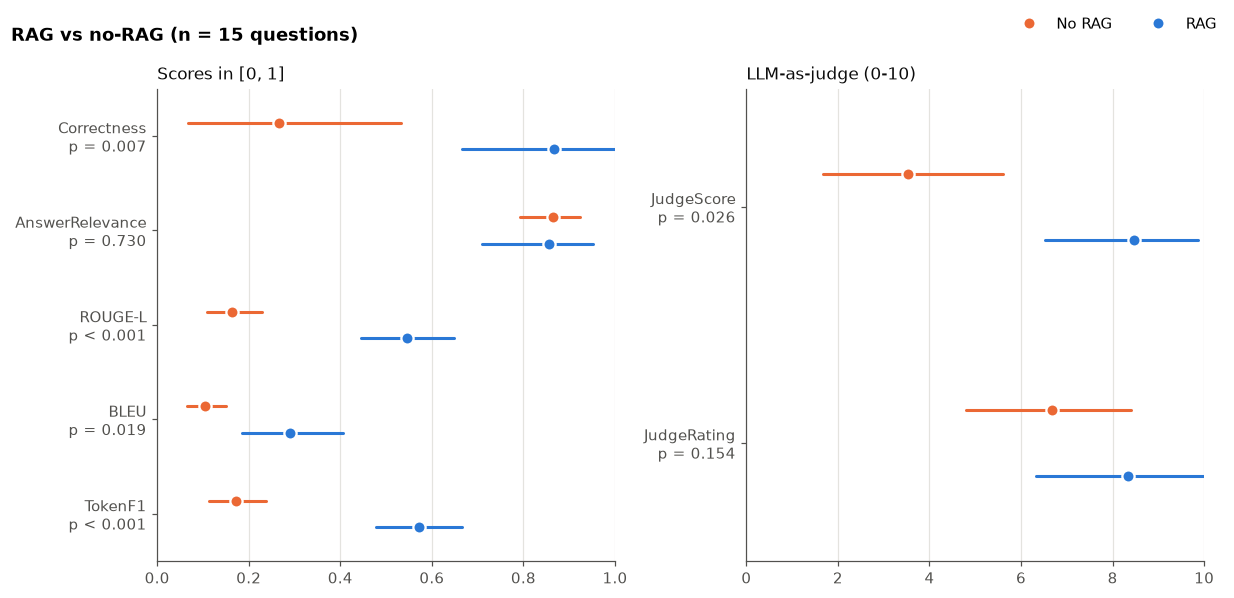

In [23]:
unit_metrics = [m for m in ["Correctness", "AnswerRelevance", "ROUGE-L", "BLEU", "TokenF1"] if m in shared]
judge_metrics = [m for m in ["JudgeScore", "JudgeRating"] if m in shared]
panels = [(unit_metrics, (0, 1), "Scores in [0, 1]"), (judge_metrics, (0, 10), "LLM-as-judge (0-10)")]
panels = [p for p in panels if p[0]]

fig, axes = plt.subplots(1, len(panels), figsize=(5.6 * len(panels), 0.75 * max(len(p[0]) for p in panels) + 1.6),
                         squeeze=False)
for ax, (metrics, xlim, title) in zip(axes[0], panels):
    for i, m in enumerate(metrics):
        for mode, dy in [("norag", -0.14), ("rag", 0.14)]:
            mean, lo, hi = bootstrap_ci(tables[mode][m])
            ax.plot([lo, hi], [i + dy] * 2, color=COLORS[mode], lw=2, solid_capstyle="round")
            ax.plot(mean, i + dy, "o", ms=8, color=COLORS[mode], mec="white", mew=1.5,
                    label=LABELS[mode] if i == 0 else None)
    ax.set_yticks(range(len(metrics)), [f"{m}\n{p_text(m)}".strip() for m in metrics])
    ax.set_ylim(len(metrics) - 0.5, -0.5)
    ax.set_xlim(*xlim)
    ax.grid(axis="y", visible=False)
    ax.set_title(title, loc="left", fontsize=11)
handles, labels = axes[0][0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", ncol=2, bbox_to_anchor=(1, 1.02))
fig.suptitle(f"RAG vs no-RAG (n = {len(tables['rag'])} questions)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save(fig, "rag_vs_norag_means.png")

### 5.2 Retrieval quality vs k (RAG)

How P@k, R@k and Hit Rate@k change with the number of retrieved chunks. P@k falls as k grows (more chunks, more noise) while R@k and Hit Rate@k can only rise.

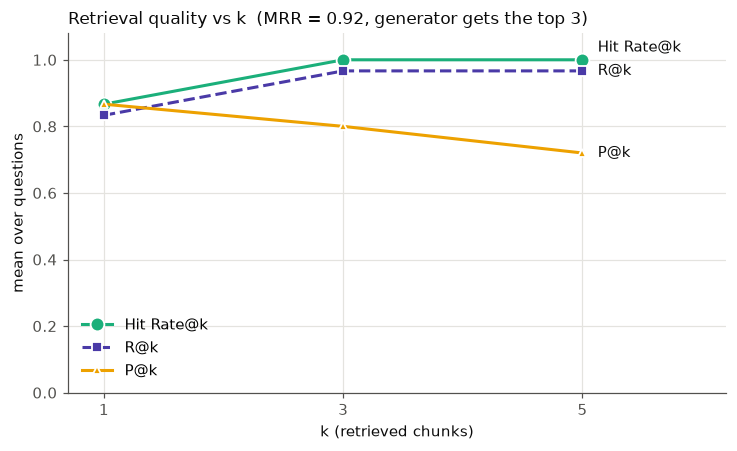

In [24]:
rag_table = tables["rag"]
# Distinct marker and dash per line, so lines that coincide (e.g. Hit = R) stay visible
series = [("Hit Rate@k", "Hit", "#1baf7a", "o", "-"), ("R@k", "R", "#4a3aa7", "s", "--"), ("P@k", "P", "#eda100", "^", "-")]
fig, ax = plt.subplots(figsize=(6.8, 4.2))
ends = []
for i, (label, prefix, color, marker, dash) in enumerate(series):
    ys = [rag_table[f"{prefix}@{k}"].mean() for k in ks]
    ax.plot(ks, ys, color=color, ls=dash, marker=marker, lw=2, ms=9 - 2 * i, mec="white", mew=1.2,
            label=label, zorder=3 + i)
    ends.append([ys[-1], label])
# Direct labels at the right end: identical end values share one label, close ones are nudged apart
merged = []
for y, label in sorted(ends):
    if merged and abs(merged[-1][0] - y) < 1e-9:
        merged[-1][1] += f" = {label}"
    else:
        merged.append([y, label])
for j in range(1, len(merged)):
    merged[j][0] = max(merged[j][0], merged[j - 1][0] + 0.07)
for y, label in merged:
    ax.annotate(label, (ks[-1], y), xytext=(10, 0), textcoords="offset points", va="center", color=INK)
ax.set(xticks=ks, xlabel="k (retrieved chunks)", ylabel="mean over questions", ylim=(0, 1.08),
       xlim=(min(ks) - 0.3, max(ks) + 1.2))
ax.set_title(f"Retrieval quality vs k  (MRR = {rag_table['MRR'].mean():.2f}, generator gets the top {GEN_K})",
             loc="left", fontsize=11)
ax.legend(loc="lower left")
fig.tight_layout()
save(fig, "retrieval_vs_k.png")

### 5.3 Per-question judge scores: no-RAG → RAG

Each row is one question, sorted by how much RAG changed its JudgeScore. Orange ring = no-RAG, blue dot = RAG; a dot inside a ring means both got the same score. Blue to the right of orange means RAG helped that question, blue to the left means it hurt.

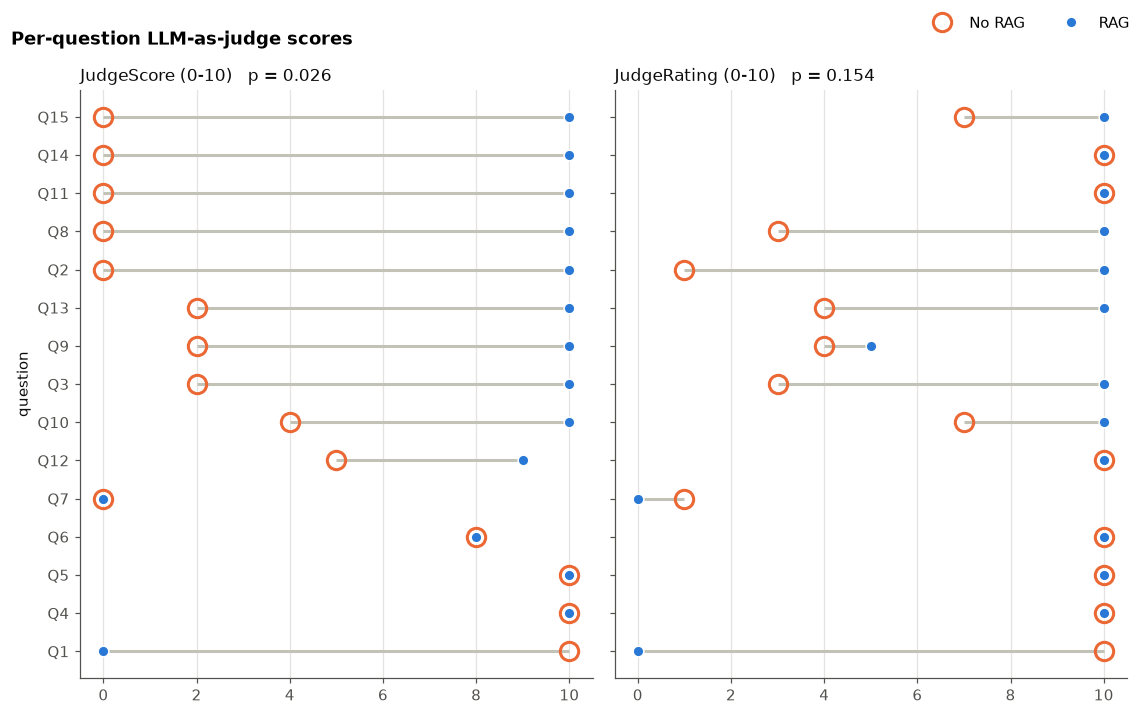

In [25]:
metrics = [m for m in ["JudgeScore", "JudgeRating"] if m in shared]
order = (tables["rag"][metrics[0]] - tables["norag"][metrics[0]]).dropna().sort_values().index
y = np.arange(len(order))

fig, axes = plt.subplots(1, len(metrics), figsize=(5.2 * len(metrics), 0.32 * len(order) + 1.6),
                         sharey=True, squeeze=False)
for ax, m in zip(axes[0], metrics):
    norag_v, rag_v = tables["norag"].loc[order, m], tables["rag"].loc[order, m]
    ax.hlines(y, norag_v, rag_v, color=CONNECTOR, lw=2, zorder=1)
    # No-RAG as a larger ring around the RAG dot, so ties (same score) stay visible
    ax.plot(norag_v, y, "o", ms=12, mfc="none", mec=COLORS["norag"], mew=2, label=LABELS["norag"], zorder=3)
    ax.plot(rag_v, y, "o", ms=7, color=COLORS["rag"], mec="white", mew=1, label=LABELS["rag"], zorder=2)
    ax.set_xlim(-0.5, 10.5)
    ax.grid(axis="y", visible=False)
    ax.set_title(f"{m} (0-10)   {p_text(m)}", loc="left", fontsize=11)
axes[0][0].set_yticks(y, [f"Q{q}" for q in order])
axes[0][0].set_ylabel("question")
handles, labels = axes[0][0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", ncol=2, bbox_to_anchor=(1, 1.02))
fig.suptitle("Per-question LLM-as-judge scores", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save(fig, "judge_per_question.png")

### 5.4 Per-question metric heatmap (RAG)

Every RAG metric in [0, 1] for every question (JudgeScore divided by 10). Columns go from retrieval (left) to the final answer (right), so a row that turns light from some column on shows where that question breaks down. Grey = not computed.

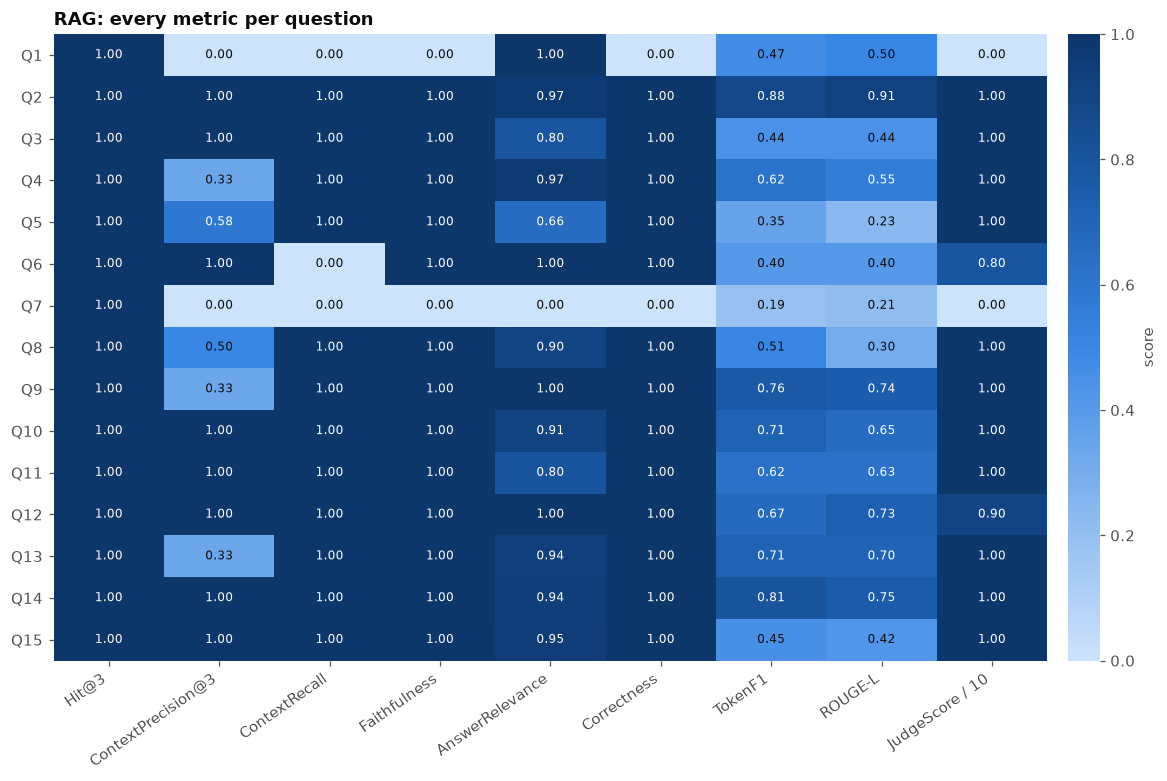

In [26]:
heat_cols = ["Hit@3", f"ContextPrecision@{GEN_K}", "ContextRecall", "Faithfulness", "AnswerRelevance",
             "Correctness", "TokenF1", "ROUGE-L", "JudgeScore"]
heat = rag_table[[c for c in heat_cols if c in rag_table]].copy()
if "JudgeScore" in heat:
    heat["JudgeScore"] = heat["JudgeScore"] / 10
    heat = heat.rename(columns={"JudgeScore": "JudgeScore / 10"})

blues = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
blues.set_bad("#e4e3df")
fig, ax = plt.subplots(figsize=(0.95 * heat.shape[1] + 2.2, 0.36 * heat.shape[0] + 1.8))
im = ax.imshow(np.ma.masked_invalid(heat.to_numpy(dtype=float)), cmap=blues, vmin=0, vmax=1, aspect="auto")
for (r, c), v in np.ndenumerate(heat.to_numpy(dtype=float)):
    if not np.isnan(v):
        ax.text(c, r, f"{v:.2f}", ha="center", va="center",
                fontsize=8, color="white" if v > 0.55 else INK)
ax.set_xticks(range(heat.shape[1]), heat.columns, rotation=35, ha="right")
ax.set_yticks(range(heat.shape[0]), [f"Q{q}" for q in heat.index])
ax.grid(False)
for side in ax.spines.values():
    side.set_visible(False)
cbar = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
cbar.outline.set_visible(False)
cbar.set_label("score", color=MUTED)
ax.set_title("RAG: every metric per question", loc="left", fontweight="bold")
fig.tight_layout()
save(fig, "rag_metric_heatmap.png")

### 5.5 Answer outcomes: pass, generation error, retrieval error

Correctness per mode. RAG failures are split as in section 3.6 (did the generator get a relevant chunk?); no-RAG has no retrieval, so its failures are not split. Questions where the judge failed are left out.

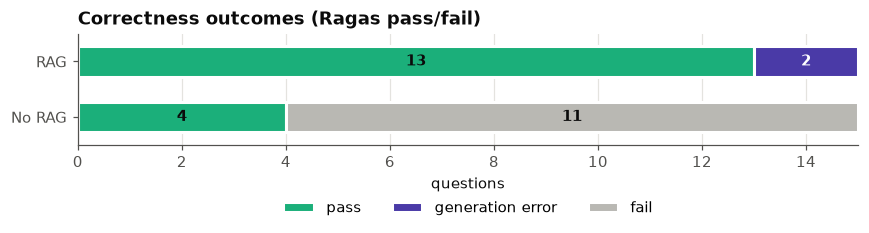

Plots saved to /Users/miguelmauricioantonio/Documents/MIA/2/ILN/PROJECT/D2_D3_Miguel_Luís/rag/evaluation/results/notebook_denso/plots


In [27]:
rag_c, norag_c = tables["rag"]["Correctness"], tables["norag"]["Correctness"]
error_counts = errors["error_type"].value_counts()
rows = {
    "RAG": [("pass", int((rag_c == 1).sum()), "#1baf7a"),
            ("generation error", int(error_counts.get("generation", 0)), "#4a3aa7"),
            ("retrieval error", int(error_counts.get("retrieval", 0)), "#eda100")],
    "No RAG": [("pass", int((norag_c == 1).sum()), "#1baf7a"),
               ("fail", int((norag_c == 0).sum()), "#b9b8b3")],
}

fig, ax = plt.subplots(figsize=(8, 2.6))
seen = set()
for i, (mode, parts) in enumerate(rows.items()):
    left = 0
    for name, count, color in parts:
        if count == 0:
            continue
        ax.barh(i, count, left=left, color=color, edgecolor="white", linewidth=2, height=0.55,
                label=None if name in seen else name)
        seen.add(name)
        ax.text(left + count / 2, i, str(count), ha="center", va="center", fontsize=10, fontweight="bold",
                color="white" if color == "#4a3aa7" else INK)
        left += count
ax.set_yticks(range(len(rows)), list(rows))
ax.set_ylim(len(rows) - 0.5, -0.5)
ax.set_xlabel("questions")
ax.set_xlim(0, max(len(rag_c), len(norag_c)))
ax.grid(axis="y", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.38), ncol=4)
ax.set_title("Correctness outcomes (Ragas pass/fail)", loc="left", fontweight="bold")
fig.tight_layout()
save(fig, "correctness_outcomes.png")
print(f"Plots saved to {PLOT_DIR}")